<a href="https://colab.research.google.com/github/Neelkamal03/Yulu_Bike_Sharing_Analysis/blob/main/Yulu_Bike_Sharing_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/Neelkamal03/Yulu_Bike_Sharing_Analysis/refs/heads/main/yulu_bike_sharing_dataset.csv"

yulu_data = pd.read_csv(url)

yulu_data.head()

In [ ]:
yulu_data.tail()

In [ ]:
yulu_data.info()

In [ ]:
yulu_data.shape

In [ ]:
yulu_data.columns

In [ ]:
#Characteristics
#Avergae rental
sum=0
for x in yulu_data["count"]:
    sum+=x
print(sum/len(yulu_data))

yulu_data["count"].mean()
yulu_data["count"].max()
yulu_data["count"].min()

In [ ]:
yulu_data.describe()

In [ ]:
#Missing values
yulu_data.isnull().sum()

In [ ]:
yulu_data["season"].value_counts()

In [ ]:
yulu_data["count"].describe()

In [ ]:
print(yulu_data["season"].unique())

print(yulu_data["weather"].value_counts())

In [ ]:
data=yulu_data.groupby("season")["count"].count()
#print(data)
row=[]
for seasons in data.index:
    row.append({seasons, data[seasons]})

table=pd.DataFrame(row, columns=["seasons", "total_rides"])
print(table)




In [ ]:
data=yulu_data.groupby("season")["count"].count().to_frame()
data["total_rides"]=data["count"]
print(data)

In [ ]:
data=yulu_data.groupby("weather")["count"].count()
data.name="total_rides_weather_wise"
data1=data.to_frame()
print(data1)

In [ ]:
data=yulu_data.groupby("weather")["count"].count().to_frame().rename(columns={"count":"total_rides"})
print(data)

In [ ]:
data=yulu_data.groupby("season")["count"].sum().to_frame()
data.columns
col=list(data.columns)
col[0]="total_rides"
data.columns=col
print(data)

In [ ]:
#which season has the highest demand
#which season has the lowest demand
h_season=yulu_data.groupby("season")["count"].count()
result=[]
result.append(h_season.idxmax())
result.append(h_season.max())
result.append(h_season.idxmin())
result.append(h_season.min())

print(result)

In [ ]:
#checking duplicate data if exist
dupli=yulu_data.duplicated()
print(dupli)
#no duplicate

In [ ]:
#How spread out is demand?
max_demand=yulu_data["count"].max()
min_demand=yulu_data["count"].min()
spread=max_demand-min_demand
print(spread)
#median
print(yulu_data["count"].median())
#standard deviation
print(yulu_data["count"].std())
#variance
print(yulu_data["count"].var())

In [ ]:
#histogram to check normal distribution
yulu_data["count"].hist()

In [ ]:
#Time-Based Questions

#convert date in date_values
date_time=yulu_data["datetime"]
#print(date_time)
datetime_values=pd.to_datetime(date_time)
yulu_data["datetime"]=datetime_values

#dt work for all not for single value
yulu_data["datetime"].dt.year

#single value
yulu_data["datetime"][4].month

In [ ]:
#Is demand increasing over time? #correlation
#Is demand decreasing over time?
#Is there seasonality in demand?

#plotting date with demand/count, like on what day how many people came, how does it change with year going forward
#hourly plot
yulu_data.plot(x="datetime", y="count")


In [ ]:
#day wise plot
group_by_date=yulu_data.groupby(yulu_data["datetime"].dt.date)["count"].sum().to_frame()
print(group_by_date)
group_by_date.plot()

In [ ]:
#for per day demand
# dt.to_period("D") ignore everything till month
#Generalize way to group by date
group_by_day=yulu_data.groupby(yulu_data["datetime"].dt.to_period("d"))["count"].sum()
print(group_by_day)
group_by_day.plot()

In [ ]:
#lets calculate whats monthly demand
date_with_month_only=yulu_data["datetime"].dt.to_period("M")
#grouping month wise
group_month_wise=yulu_data.groupby(date_with_month_only)
#adding demand month wise
demand_month_wise=group_month_wise["count"].sum()
print(demand_month_wise.head())
demand_month_wise.plot()


In [ ]:
#lets plot average demand every month
avg_per_month=demand_month_wise/30 #you can divide array
#for x in demand_month_wise:
 #avg_per_month.append(x/30)

print(avg_per_month) # the average number of rides per day in a month
avg_per_month.plot()



avg_demand_per_month=group_month_wise["count"].mean() #average number of rides in a hour per month
print(avg_demand_per_month)


In [ ]:
d=demand_month_wise.to_frame()
# d["datetime"] dont work because since you grouped by month, grouby actually create the index by which you are grouping
# if you want to seperate datetime
d1=demand_month_wise.to_frame().reset_index()
d1
d1["count"]
#also work d1.plot()
#d1.plot(x="datetime", y="count")
#if you want to plot something with index as x
d1.plot()

In [ ]:
data123 = {
    "datetime": ["2011-01", "2011-02", "2011-03"],
    "count": [12000, 15000, 18000],
    "temp": [18, 22, 25],
    "humidity": [60, 55, 50]
}
data2=pd.DataFrame(data123)
print(data2)
data2.plot()

In [ ]:
#demand year wise
group_by_year=yulu_data["datetime"].dt.to_period("M")
#print(group_by_year.unique())
demand_year_wise=yulu_data.groupby(group_by_year)["count"].sum()
print(demand_year_wise)
demand_year_wise.plot()
#print(demand_year_wise)

#demand_year_wise


In [ ]:
#Is there seasonality in demand?
#checking demand season wise
#print(yulu_data["season"])
#seasons is basically a numerical values ranging from 1--4
no_of_season=yulu_data["season"].unique()
#print(no_of_season)
# so there are 4 season
#plot demand according to season
demand_by_season=yulu_data.groupby("season")["count"].sum()
#print(demand_by_season)
#demand_by_season.plot()

#Also season 1 can have 3 months ofdata, season 2 could have 6 months so overall count will go will up so we cant say season 3 has highest demand,
#so thats why when we check season wise data,
#we should check mean, it gives us a clear indicator of no of rides per season
season_summary=yulu_data.groupby("season")["count"].agg(["count", "sum", "mean"])
print(season_summary)
season_summary.plot(y="mean", kind="bar")


In [ ]:
#Hey so now we can see the avergae number of rides differ according to seasons, but now we check if this fluctation significant or not to see weather season actually have a higher
#weight in affecting no of rides
#For checking if season affect no of rides we use ANOVA test
#ANOVA mainly answers: "Does season matter?"
#No effect
#or
#There is an effect
#ANOVA:
#"Is season important?"

#Effect size:
#"How important is season?"

#season wise buckets
season1=yulu_data[yulu_data["season"]==1]["count"]
season2=yulu_data[yulu_data["season"]==2]["count"]
season3=yulu_data[yulu_data["season"]==3]["count"]
season4=yulu_data[yulu_data["season"]==4]["count"]

#no_of_rides_season_wise=[season1.sum()/len(season1), season2.sum()/len(season2), season3.sum()/len(season3), season4.sum()/len(season4)]
#no_of_rides_season_wise1=[season1.mean(), season2.mean(), season3.mean(), season4.mean()]
#print(no_of_rides_season_wise1)
#print(no_of_rides_season_wise)

season1.describe()

In [ ]:
#calculating anova
from scipy.stats import f_oneway

f_stat, p_stat=f_oneway(season1, season2, season3, season4)
print(f_stat)
print(p_stat)

if(p_stat<0.05):
  print("There is an effect")
else:
  print("There is no effect")

#this proves season has a very high effect on demand, p_value comes out to be 6.16*10^-149
#by anova test we can say followings
#Demand differ significantly across season
#Season is useful for predicting demands
#Season 3 has highest average demand
#Season 1 has lowest average demand

In [ ]:
# Which months have the highest demand?
# Which months have the lowest demand?
# Which hours have the highest demand?
# Which hours have the lowest demand?
month_wise_demand=yulu_data.groupby(yulu_data["datetime"].dt.to_period("M"))["count"].agg(["count", "sum", "mean"])
#print(month_wise_demand)
#month_wise_demand.plot(kind="bar", y="mean")
#month with highest number rides per hour in a month
#month_wise_demand["mean"].idxmax()

#now we check if month actually affects number of rides by anova test
month_wise_demand1=yulu_data.groupby(yulu_data["datetime"].dt.to_period("M"))["count"]
print(month_wise_demand1.describe())
group=[]
# for x in month_wise_demand1:
#   group.append(x[1])
# # The * operator unpacks a list.
# f_stat_month, p_stat_month=f_oneway(*group)
# print(f_stat_month)
# print(p_stat_month)

# if(p_stat_month<0.05):
#   print("Month affects demand")
# else:
#   print("Month does not affect demand")

#Anova is not really useful in this, anova work for categorical data that repeats,
#but here months and demand of company grows, so doing for a month dont really give us any benefit
#Also there are all unique values, not categorical or repeating value so anova is useless here

In [ ]:
## Which months have the highest demand?
# Which months have the lowest demand?
#Here question is which month has highest demand

#so we have to go month wise
month_wise_data=yulu_data.groupby(yulu_data["datetime"].dt.month)["count"].agg(["count", "sum", "mean"])
#print(month_wise_data)
highest_demand_month=[month_wise_data["mean"].max(), month_wise_data["mean"].idxmax()]
lowest_demand_month=[month_wise_data["mean"].min(), month_wise_data["mean"].idxmin()]
print(highest_demand_month)
print(lowest_demand_month)
month_wise_data.plot(kind="bar", y="mean")
# Month 6 has the highest average demand of 242 rides/hour.
# Month 1 has the lowest average demand of 90 rides/hour.
# Demand generally increases/decreases during ...

#lets calculate anova, does month affect rides per hour
month_wise=yulu_data.groupby(yulu_data["datetime"].dt.month)["count"]
group1=[]
for x in month_wise:
  group1.append(x[1])
f_stat2, p_stat2=f_oneway(*group1)
print(f_stat2)
print(p_stat2)
if(p_stat2<0.05):
  print("Month affects demand")
else:
  print("Month does not affect demand")

In [ ]:
# Which hours have the highest demand?
# Which hours have the lowest demand?
#lets group by hours
group_by_hours=yulu_data.groupby(yulu_data["datetime"].dt.hour)
demand_every_hour=group_by_hours["count"].agg(["count", "sum", "mean"])
#print(demand_every_hour.head(3))
#So we can for example at 10am-11am morning near about 175 rides are booked everyday
#hour wise plot
demand_every_hour.plot(y="mean", kind="bar")
highest_demanding_hour=[demand_every_hour["mean"].idxmax(), demand_every_hour["mean"].max()]
lowest_demanding_hour=[demand_every_hour["mean"].idxmin(), demand_every_hour["mean"].min()]
print(highest_demanding_hour)
print(lowest_demanding_hour)

#Anova test
group3=[]
for x in group_by_hours["count"]:
  group3.append(x[1])
f_stat3, p_stat3=f_oneway(*group3)
print(f_stat3)
print(p_stat3)

if(p_stat3<0.05):
  print("The hours have a signicant impact on demand hourly")
else:
  print("hours do not affect")
# Demand is lowest during early morning hours (around 4 AM).
# Demand starts increasing after 6 AM.
# A first peak is observed around 8 AM, likely corresponding to commuting hours.
# The highest demand occurs at 5 PM (17:00), indicating strong evening commuting demand.
# Demand gradually declines after 7 PM.

In [ ]:
# Weather
# Does weather affect demand?
# Which weather condition has the highest demand?
# Which weather condition has the lowest demand?
# How much demand drops in bad weather?
weather=yulu_data["weather"]
weather.unique()
#there are 4 types of weather
#Does weather affect demand
demand_acc_weather=yulu_data.groupby("weather")["count"]
demand_acc_weather.describe()
avg_demand_in_weather=demand_acc_weather.agg(["sum", "mean"])
print(avg_demand_in_weather)
avg_demand_in_weather.plot(y="mean", kind="bar")
#Maximum demand for rentals is in "1" and lowest is in "3"
#Anova to check if demand change according to weather is significant enough
demand_acc_weather
group4=[]
for weather,demand in demand_acc_weather:
    group4.append(demand)
f_stat4, p_stat4=f_oneway(*group4)
print(f_stat4)
print(p_stat4)

if(p_stat4<0.05):
  print("Weather affects rentals")
else:
  print("Weather dont affect rentals")

#How much demand drops due to bad weather
drop=avg_demand_in_weather["mean"].max()-avg_demand_in_weather["mean"].min()
print(drop)
drop_per=(drop/avg_demand_in_weather["mean"].max())*100
print(drop_per,"%")

In [ ]:
workingday=yulu_data["workingday"]
workingday.unique()
workingday_demand=yulu_data.groupby("workingday")["count"]
workingday_stat=workingday_demand.agg(["count","sum", "mean"])
print(workingday_stat)
workingday_stat.plot(y="mean", kind="bar")
#checking if working day has a significant impact or not on demand using anova test
group5=[]
for workingday, demand in workingday_demand:
  group5.append(demand)
f_workingday,p_workingday=f_oneway(*group5)
print(f_workingday)
print(p_workingday)
if(p_workingday<0.05):
  print("Has effect")
else:
  print("No effect")
# Working Day
# Is demand higher on working days?
# Is demand lower on non-working days?
# Is the difference meaningful?
# Holiday
# Does demand change on holidays?
# Are holidays associated with lower rentals?
# Are holidays associated with higher rentals?
#Answer to above question
#So we conclude that working day dont have effect on the number of rentals
#No, demand is almost same both working and non_working
#No
#No
#No
#No

0.394453644967249
when temp increases demand tends to increase
         temp                         count
          min    max       mean        mean
season                                     
1        0.82  29.52  12.530491  116.343261
2        9.84  38.54  22.823483  215.251372
3       15.58  41.00  28.789111  234.417124
4        5.74  30.34  16.649239  198.988296


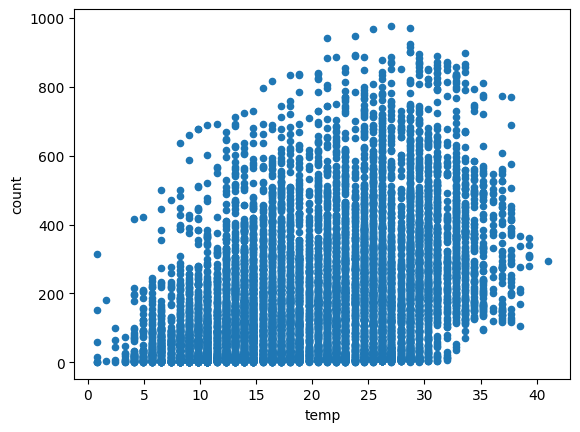

In [38]:
# Temperature
temp=yulu_data["temp"]
#print(temp.value_counts())
# Does temperature affect demand?
#find correlation between temp and count
correlation=yulu_data["temp"].corr(yulu_data["count"])
print(correlation)
if(correlation>0):
  print("when temp increases demand tends to increase")
elif(correlation<0):
  print("when temp increases demand tends to decrease")
else:
  print("No correlation between variable")
#Scatterplot
yulu_data.plot.scatter(x="temp", y="count")
#By looking at the graph correlation cannot be fully used to answer this question
#Correlation not useful enough, fully cant be answered just by correlation
temp_range=[yulu_data["temp"].min(), yulu_data["temp"].max()]

#This is one way to handle ranging data like temperature
def temp_cat(temp):
    if(temp<15):
       return "Cold"
    elif(temp>=15 and temp<25):
       return "Pleasant"
    elif(temp>=25 and temp<=35):
      return "Warm"
    else:
      return "Hot"
temp_category=[]
for x in yulu_data["temp"]:
  temp_category.append(temp_cat(x))
# print(len(temp_category))
# print(len(yulu_data))

yulu_with_temp_cat=yulu_data
yulu_with_temp_cat["temp_category"]=temp_category
yulu_with_temp_cat.head()
# Do rentals increase as temperature increases?
# Is there an optimal temperature range?
# Does demand fall at extremely high temperatures?

#lets check one thing how much temperature ranges season wise
temp_min_max=yulu_data.groupby("season").agg({
    "temp":["min", "max", "mean"],
    "count":["mean"]
})
print(temp_min_max)
#you can see season-1,4 ranges from 0--30 approx can be considered

/tmp/ipykernel_744/659999236.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  group_by_temp=yulu_data.groupby("temp_range")


            count     sum        mean
temp_range                           
(0, 10]      1259   92141   73.185862
(10, 20]     4049  609233  150.465053
(20, 30]     4334  968265  223.411398
(30, 40]     1243  415543  334.306516
(40, 50]        1     294  294.000000
486.79534402581163
0.0
temp_range significantly affect rentals


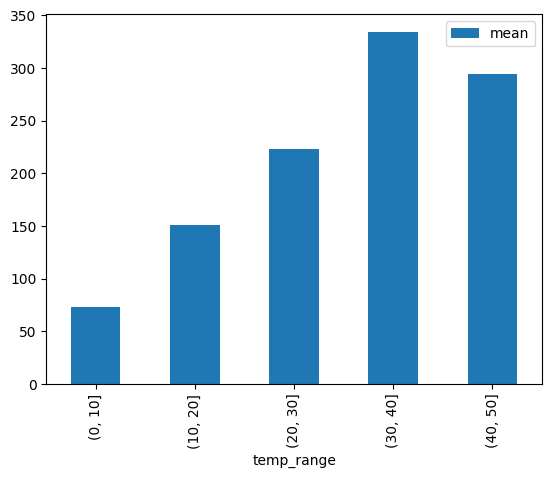

In [39]:
# Temperature
# Does temperature affect demand? No graph is basically U type mean , for some temp ranges its increasing and for some not
# Do rentals increase as temperature increases? No, rentals gradually increases as temperature increase till 40,
# once it reaches beyond 40 we dont have enough data because observation are really less
# Is there an optimal temperature range? yes, its 30-40
# Does demand fall at extremely high temperatures? The available data suggests demand may fall at temperatures above 40°C,
#but there is only one observation in this range, so no reliable conclusion can be drawn.
#Dividing temperature into temperature ranges [0-10], [10-20], [20-30], [30-40]
#yulu_data["temp_range"]=pd.cut(yulu_data["temp"], bins=5)
#range of temp [0-42], so temp divided in 5 parts of 8..approx
#below is custom divison
yulu_data["temp_range"]=pd.cut(yulu_data["temp"], bins=[0,10,20,30,40,50])
group_by_temp=yulu_data.groupby("temp_range")
demand_by_temp=group_by_temp["count"].agg(["count","sum", "mean"])
demand_by_temp.plot(y="mean",kind="bar")
print(demand_by_temp)

#Anova test for checking does temp_range significantly affects demand or not
group6=[]
for temp_range, demand in group_by_temp["count"]:
   group6.append(demand)
f_temp, p_temp=f_oneway(*group6)
print(f_temp)
print(p_temp)
if(p_temp<0.05):
  print("temp_range significantly affect rentals")
else:
  print("Not much effect")

[0, 100]
                count     sum        mean
humidity_range                           
(0, 20]            56   13447  240.125000
(20, 40]         1560  453412  290.648718
(40, 60]         3564  786017  220.543490
(60, 80]         3382  579255  171.275872
(80, 100]        2302  252722  109.783666
               count                    
               count     sum        mean
humidity_range                          
(0, 20]           56   13447  240.125000
(20, 40]        1560  453412  290.648718
(40, 60]        3564  786017  220.543490
(60, 80]        3382  579255  171.275872
(80, 100]       2302  252722  109.783666
297.60715734602906
2.778718722470489e-243
humidity has effect on demand
51.72 %


/tmp/ipykernel_744/1642643217.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groupby_humidity=yulu_data.groupby("humidity_range")


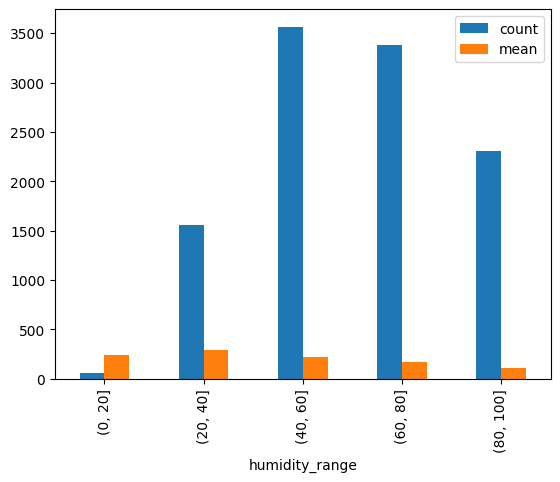

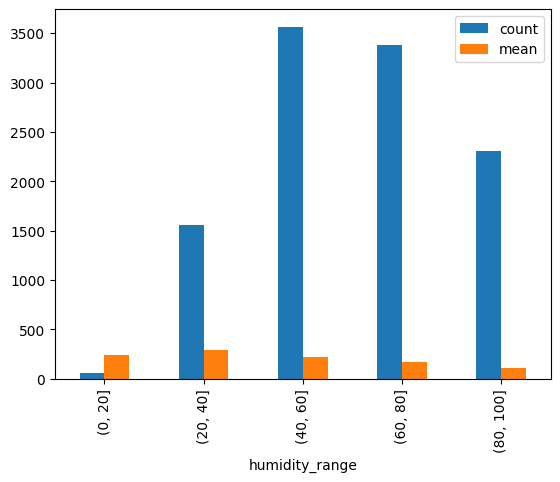

In [40]:
# Humidity
# Does humidity affect demand? yes, demand is highest when humidity is 20-40 but demand starts to go down as humidity increases
# Do rentals decrease when humidity increases? No, there is small decrease
humidity=yulu_data["humidity"]
print([humidity.min(), humidity.max()])
#lets divide humidity into buckets of 10
humidity_range=pd.cut(humidity, bins=[0,20,40,60,80,100])
yulu_data["humidity_range"]=humidity_range
#lets group based on humidity
groupby_humidity=yulu_data.groupby("humidity_range")
rentals_by_humidity=groupby_humidity.agg({
    "count":["count","sum", "mean"]
})
rentals_by_humidity1=groupby_humidity["count"].agg(["count","sum", "mean"])
print(rentals_by_humidity1)
print(rentals_by_humidity)
rentals_by_humidity["count"][["count","mean"]].plot(kind="bar")
rentals_by_humidity1[["count", "mean"]].plot(kind="bar")
#If you want to group two columns together [[]]
#checking does humidity has significant effect on demand with anova
group7=[]
for humidity, demand in groupby_humidity["count"]:
  group7.append(demand)

f_humidity, p_humidity=f_oneway(*group7)
print(f_humidity)
print(p_humidity)
if(p_humidity<0.05):
  print("humidity has effect on demand")
else:
  print("humidity has no effect on demand")

overall_avg = yulu_data["count"].mean()
max_demand_humidity=rentals_by_humidity["count"]["mean"].max()
print(round(((max_demand_humidity-overall_avg)/overall_avg)*100,2),"%")

[0.0, 56.9969]
0.10136947021033277
                  count     sum        mean
windspeed_range                            
(-0.057, 7.125]    3219  516091  160.326499
(7.125, 14.249]    3219  621258  192.997204
(14.249, 21.374]   2953  637864  216.005418
(21.374, 28.498]   1068  223899  209.643258
(28.498, 35.623]    338   70778  209.402367
(35.623, 42.748]     60   11194  186.566667
(42.748, 49.872]     25    3677  147.080000
(49.872, 56.997]      4     715  178.750000
216.00541821876058
(14.249, 21.374]
147.08
(42.748, 49.872]
7.767247285123553
7.529782536042733e-30
Have significant effect


/tmp/ipykernel_744/918491378.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rentals_by_windspeed=yulu_data.groupby("windspeed_range")["count"].agg(["count", "sum", "mean"])


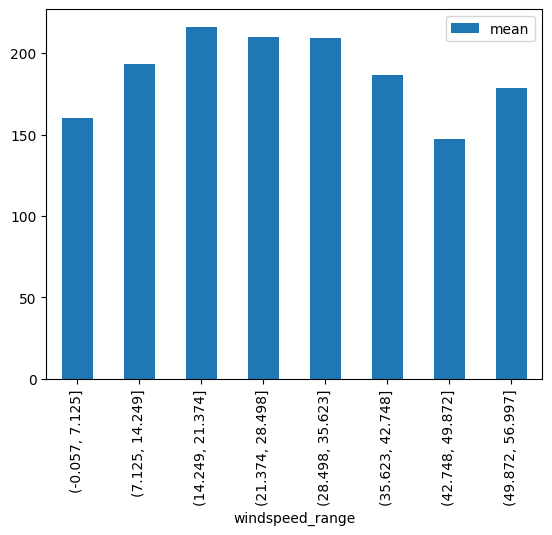

In [41]:
# Windspeed
# Does windspeed affect demand? By anova-test we it has a significant impact on number of rentals, so we can for 14-27--nextline
# we have the maximum demand we can say that because we have enough data for it.
# Do rentals decrease on windy days? For this we can really say because the demand is lowest when 42-49 but we also dont have enough observation to clearly state that,
# it may change if we get more data
windspeed=yulu_data["windspeed"]
# print(windspeed)
range=[windspeed.min(), windspeed.max()]
print(range)
corr=windspeed.corr(yulu_data["count"])
print(corr)
#yulu_data.plot.scatter(x="windspeed", y="count")
#yulu_data.plot.scatter(x="windspeed",y="count")
#yulu_data[["windspeed", "count"]].plot(kind="scatter", x="windspeed", y="count")

#Dividing windspeed in buckets
# Create the ranges (bins) ✅
# Find which range each value belongs to ✅
# Replace each value with its bucket label ✅
windspeed_bucket=pd.cut(yulu_data["windspeed"], bins=8)
yulu_data["windspeed_range"]=windspeed_bucket
# .agg() lets you apply multiple aggregate functions at once
rentals_by_windspeed=yulu_data.groupby("windspeed_range")["count"].agg(["count", "sum", "mean"])
# rentals_by_windspeed is a dataframe
print(rentals_by_windspeed)
#So an average of 209 rides are booked per hours when windspeed is between 28--36
print(rentals_by_windspeed["mean"].max())
print(rentals_by_windspeed["mean"].idxmax())
print(rentals_by_windspeed["mean"].min())
print(rentals_by_windspeed["mean"].idxmin())
rentals_by_windspeed.plot(kind="bar" ,y="mean")
#Lets check if wind affect on demand is significant or not
#So for a particular range of windspeed we have a array/list of values right
group8=[]
for windspeed, demand in yulu_data.groupby("windspeed")["count"]:
    group8.append(demand)

f_value, p_value=f_oneway(*group8)
print(f_value)
print(p_value)
if(p_value<0.05):
  print("Have significant effect")
else:
  print("No significant effect")

In [42]:
# Series vs DataFrame (Pandas)
# A DataFrame is a table containing multiple columns and rows.
# like yulu_data is a whole table
# Selecting a single column using yulu_data["windspeed"] returns a Series, not a DataFrame.
# A Series can be thought of as an collection of index → value pairs, similar to a dictionary/map
# Series only have index and one column data, but in memory its written as index and values, so when you do yulu_data["windspeed"] it mean index--------values, its not windspeed
# df["windspeed"]
#         ↓
# Series
# ├── Index
# └── Values

# If you multiple column you have dataFrames
# If you want to create a table out of multiple columns
yulu_data[["windspeed", "count"]]

,windspeed,count
0,0.0000,16
1,0.0000,40
2,0.0000,32
3,0.0000,13
4,0.0000,1
...,...,...
10881,26.0027,336
10882,15.0013,241
10883,15.0013,168
10884,6.0032,129


0.008878650849278464
-0.05503541815497814
0.2586885507660315
0.1906100203714225
0.09675806284610494
-0.13591768027504594
0.007261124168235936


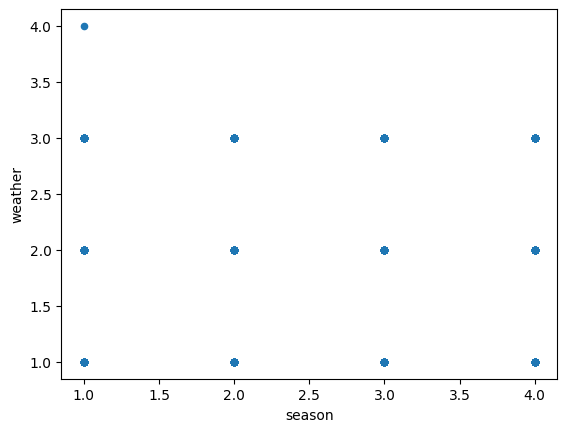

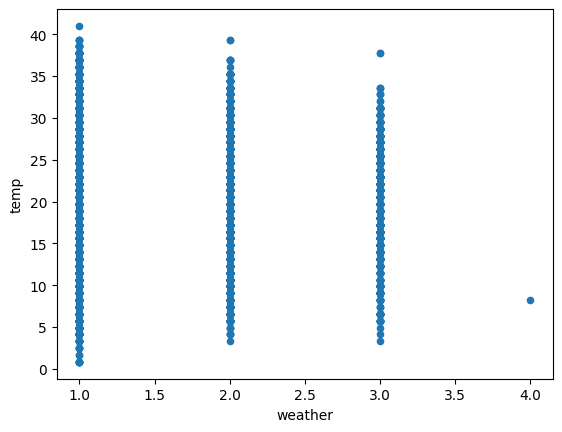

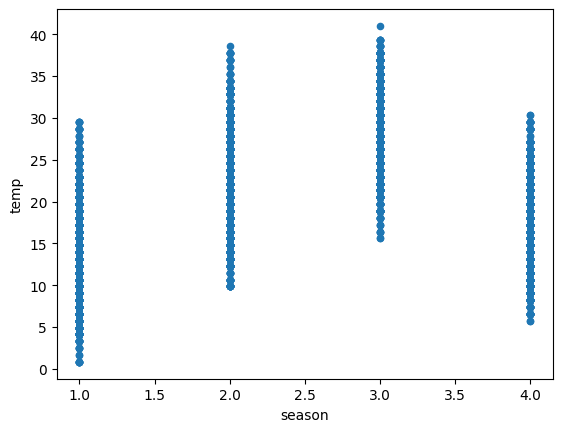

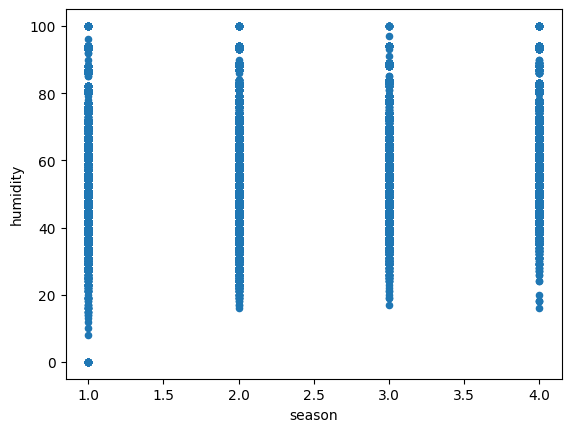

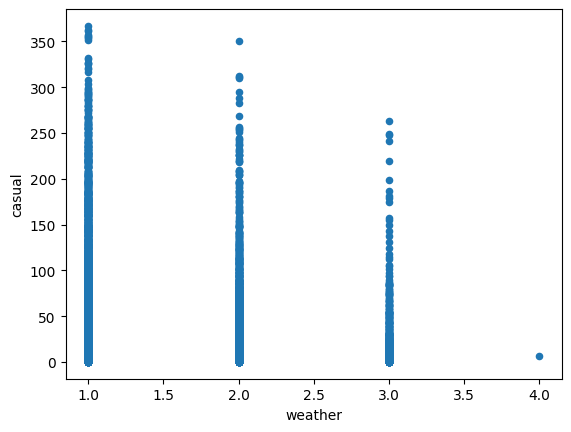

In [43]:
# Relationships Between Predictors
# Is weather dependent on season?
# Does humidity vary by season?
# Does temperature vary by season?
# Are some predictors strongly related to each other?

# Season and Weather both categorical values
# Analysis of season and weather will answer how weather pattern are changed in a season
# lets say weather changes as season changes, we will weather is highly dependent on season
# If season changes weather dont change, the mean of weather remain same, that means they are independent
# We can check dependency by checking correlation
season=yulu_data["season"]
weather=yulu_data["weather"]
print(season.corr(weather)) #corr=0.008878650849278464
# we can see correlation is near 0.0088, near about zero only, so there is no relation between them they are highly independent
# lets draw scatterplot for much more info
yulu_data.plot(kind="scatter", x="season", y="weather")

# Lets check if weather is related to temp, windspeed , humidity
print(weather.corr(yulu_data["temp"])) #corr=-0.055
yulu_data.plot.scatter(x="weather", y="temp")

# Lets check if season and temperature
print(season.corr(yulu_data["temp"])) #corr=0.25
yulu_data.plot.scatter(x="season", y="temp")
# well temperature range does increase with change in season till season 3 but then temperature decreases, so its not strictly increasing correlation

# season and humidity
print(season.corr(yulu_data["humidity"]))#corr=0.19
yulu_data.plot.scatter(x="season", y="humidity")
# humidity also dont really changes with season

# lets check casual users with season
# its possible that causal users will rent only in certain season or so
print(season.corr(yulu_data["casual"])) #corr=0.096
# Casual users also dont care about season

# lets check casual user care about weather
print(weather.corr(yulu_data["casual"])) #corr=-0.13
yulu_data.plot.scatter(x="weather", y="casual")
# we could a little relation, when weather increases/changes the casual user decreases, meaning casual user dont prefer later weather

# lets check how does latter weather looks like
print(weather.corr(yulu_data["windspeed"])) #corr=0.0072
# windspeed also not dependent on weather




# Now this whole section was a big mistake
# Numerical values → Correlation is meaningful

# Category labels encoded as numbers → Correlation is usually not meaningful

# For category--category values use crosstab + chi-square (season and weather)
# For category--numerical values use mean + Anova (season and temp)
# For numerical--numerical values use correlation + scatterplot

In [44]:
# Relationships Between Predictors
# Is weather dependent on season?  No they are mostly independ because weather distribution looks similar across all season
season=yulu_data["season"]
weather=yulu_data["weather"]
# Since both are categorical value we use crosstab +chi-square
season_weather=pd.crosstab(yulu_data["season"], yulu_data["weather"])
print(season_weather)
# we see weather distribution is same in every season, so weather is independent of season

from scipy.stats import chi2_contingency
chi2 , p , dof, expected=chi2_contingency(season_weather)
print("chi-square", chi2)
print("p-value", p)

if p < 0.05:
    print("Weather depends on season")
else:
    print("Weather is independent of season")

weather     1    2    3  4
season                    
1        1759  715  211  1
2        1801  708  224  0
3        1930  604  199  0
4        1702  807  225  0
chi-square 49.158655596893624
p-value 1.549925073686492e-07
Weather depends on season


season
1    12.530491
2    22.823483
3    28.789111
4    16.649239
Name: temp, dtype: float64


<Axes: xlabel='season'>

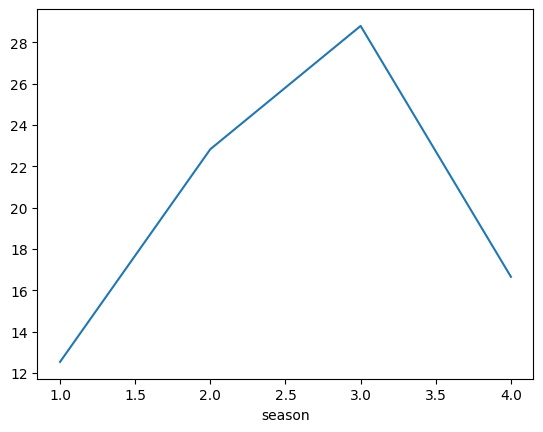

In [45]:
# Season and temp
# category and numerical
season_temp=yulu_data.groupby("season")["temp"].mean()
print(season_temp)
season_temp.plot()
# Does temperature vary by season?
# temperature increases with season theN decreses after season 3

season
1    56.297841
2    60.852909
3    64.123674
4    66.173738
Name: humidity, dtype: float64
234.417124039517
3
season  humidity_range
1       (0, 20]            85.933333
        (20, 40]          167.561313
        (40, 60]          112.192898
        (60, 80]          100.683051
        (80, 100]          85.037825
2       (0, 20]           461.823529
        (20, 40]          353.481188
        (40, 60]          245.009877
        (60, 80]          168.580049
        (80, 100]         113.035654
3       (0, 20]           361.000000
        (20, 40]          395.136842
        (40, 60]          308.503153
        (60, 80]          199.584507
        (80, 100]         107.248544
4       (0, 20]           314.800000
        (20, 40]          341.738220
        (40, 60]          245.931447
        (60, 80]          185.114929
        (80, 100]         122.503226
Name: count, dtype: float64
461.8235294117647
(np.int64(2), Interval(0, 20, closed='right'))


/tmp/ipykernel_744/57287066.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  max_avg_demand_acc_humidity_season=yulu_data.groupby(["season", "humidity_range"])["count"].mean()


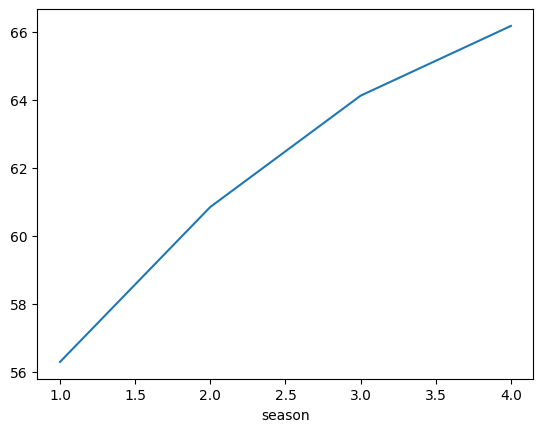

In [46]:
# Does humidity vary by season?
# Season category and humidity numerical
season_humidity=yulu_data.groupby("season")["humidity"].mean()
print(season_humidity)
season_humidity.plot()
# Humidity changes significantly with change in season, we see when season change humditiy tends to increase
# Are some predictors strongly related to each other?
# Season and humidity are strongly related to each other

# Is there a particular season and humidity where avg demand is highest
highest_avg_demand=yulu_data.groupby("season")["count"].mean()
print(highest_avg_demand.max())
print(highest_avg_demand.idxmax())

# For season 3 avg demand is highest, lets see for which humidity range its the highest, since humidity range is also categorical
max_avg_demand_acc_humidity_season=yulu_data.groupby(["season", "humidity_range"])["count"].mean()
print(max_avg_demand_acc_humidity_season)
print(max_avg_demand_acc_humidity_season.max())
print(max_avg_demand_acc_humidity_season.idxmax())

In [47]:
# Business Questions
# What are the top demand drivers?
# Among all factors,
# which ones drive demand the most?
# Whats regression?
# Given season, temp, humidity, hour, predict demand, that what regression does it takes all of these and predict the demand for new data
# Demand=50+5Temp−2Humidity
# Coefficient = 5, coefficient is also like weight affect of that parameter on demand

# means:

# If temperature increases by 1 unit,
# expected demand increases by 5.
# Can I rank factors by coefficient? like higher coefficient affect higher---- No
# Suppose regression gives:

# Temp coefficient = 5
# Humidity coefficient = -2
# Hour coefficient = 15

# Can we conclude:

# Hour > Temp > Humidity  Not necessarily.
# Because:

# Temp ranges from 0-40
# Humidity ranges from 0-100
# Hour ranges from 0-23

# The scales are different.

# So raw coefficients can be misleading.
# So for comparing weights or coefficient
# Standardized coefficients

# or

# Feature importance

# Coefficient sign
# → Direction of effect

# Coefficient magnitude
# → Strength per unit

# Standardized coefficient / feature importance
# → Fair comparison of drivers

# Percentage impact
# → Business interpretation

In [48]:
# Business Questions
# What are the top demand drivers?
# Among all factors,
# which ones drive demand the most?

from sklearn.linear_model import LinearRegression
#This part is basically to seperate table in factor and target variable
yulu_data["Y"]=yulu_data["datetime"].dt.year
yulu_data["M"]=yulu_data["datetime"].dt.month
yulu_data["D"]=yulu_data["datetime"].dt.dayofweek
yulu_data["H"]=yulu_data["datetime"].dt.hour
season_dummies=pd.get_dummies(yulu_data["season"], prefix="season")
month_dummies=pd.get_dummies(yulu_data["M"], prefix="month")
day_dummies=pd.get_dummies(yulu_data["D"], prefix="Day_of_week")
hour_dummies=pd.get_dummies(yulu_data["H"], prefix="Hour")
weather_dummies=pd.get_dummies(yulu_data["weather"],prefix="weather")
temperature_dummies=pd.get_dummies(yulu_data["temp_range"], prefix="temp_range")
humidity_dummies=pd.get_dummies(yulu_data["humidity_range"], prefix="humidity_range")
windspeed_dummies=pd.get_dummies(yulu_data["windspeed_range"], prefix="windspeed_range")
hour_dummies=pd.get_dummies(yulu_data["H"], prefix="Hour")
x1=yulu_data[["Y", "holiday", "workingday",  "temp",
     "humidity", "windspeed"]]
x1=pd.concat([x1,season_dummies,month_dummies, day_dummies,hour_dummies, weather_dummies, temperature_dummies, windspeed_dummies, humidity_dummies], axis=1)
y=yulu_data["count"]

# model.fit(X, y)

# it might look like:

# model
# ├── fit()
# ├── predict()
# ├── score()
# ├── coef_ = [12.5, -3.1, 0.8, ...]
# ├── intercept_ = 45.7
model=LinearRegression()
model.fit(x1,y)
# dir(model) show all variable things inside the object
model.__dict__
model.coef_
# model.predict(...)
# in creating values for regression model we generally tends to avoid factor which are highly correlated like temp & atemp, thats why factor to factor comparison become important
# After training, the model is basically storing:
# Demand =
# constant
# + weight₁ × Temp
# + weight₂ × Humidity
# + weight₃ × Hour
# + ...
for feature, coeff in zip(x1, model.coef_):
  print(feature,":",round(coeff,2))

# We can see when year increase the demand increases near by 82
print(round(model.score(x1,y),3))
print(x1.columns)
print(len(x1.columns))
# Demand =
# 50
# + 6 × Temp
# - 2 × Humidity
# + 8 × Hour
# Then R² asks:
# How well do these predicted values
# follow the actual values?
# If the predictions closely follow the actual demand:
# R² → high
# If the predictions miss the pattern badly:
# R² → low
# The regression model creates a formula
# using coefficients (weights).


# R^2 is think your model ran on 100 rows,
# In that it was able to explain 38% of pattern like if temp was high, humidity was demand increased like that it was able to uncover 38% pattern
# For 64% pattern it was not able to say how they changed demand

# For this the R^2 is high because our predicted values near to actual value
# Actual	Predicted
# 100	     105
# 200	     195
# 300	     290
# 400	     410

# For this the R^2 is low because our predicted values far away to actual value
# Actual	Predicted
# 100	     250
# 200	     250
# 300	     250
# 400	     250


Y : 88.88
holiday : -4.07
workingday : 2.09
temp : 5.2
humidity : -0.83
windspeed : 0.13
season_1 : -31.4
season_2 : 9.02
season_3 : -4.53
season_4 : 26.91
month_1 : -31.78
month_2 : -11.59
month_3 : 11.97
month_4 : -3.88
month_5 : 14.93
month_6 : -2.02
month_7 : -19.87
month_8 : -9.38
month_9 : 24.72
month_10 : 18.66
month_11 : 7.17
month_12 : 1.08
Day_of_week_0 : -6.39
Day_of_week_1 : -3.57
Day_of_week_2 : -0.11
Day_of_week_3 : 2.76
Day_of_week_4 : 5.34
Day_of_week_5 : 10.78
Day_of_week_6 : -8.8
Hour_0 : -125.97
Hour_1 : -142.9
Hour_2 : -153.87
Hour_3 : -165.82
Hour_4 : -166.71
Hour_5 : -150.49
Hour_6 : -91.38
Hour_7 : 41.94
Hour_8 : 185.93
Hour_9 : 37.47
Hour_10 : -17.85
Hour_11 : 9.86
Hour_12 : 50.73
Hour_13 : 46.04
Hour_14 : 28.74
Hour_15 : 39.57
Hour_16 : 102.76
Hour_17 : 260.16
Hour_18 : 226.66
Hour_19 : 115.31
Hour_20 : 33.07
Hour_21 : -17.45
Hour_22 : -53.28
Hour_23 : -92.51
weather_1 : 62.47
weather_2 : 52.38
weather_3 : -1.01
weather_4 : -113.84
temp_range_(0, 10] : 52.43
te

In [49]:
# Some theory

# Conversation with Gemini
# how will the graph of multi linear regression look like, write the equation first and then plot
# The equation for Multiple Linear Regression is:
# Y=a+(a1*x1)+(a2*x2)+(a3*x3)+....
# Linear regression model always creates flat sheet
# And it tries to align the flatsheet so that it can cover most of the points
# How do we know if our sheet is "covering" the data well?We don't just guess;
# we use specific metrics to measure "coverage":$R^2$ (Coefficient of Determination):
# This tells you what percentage of the variance in your target ($Y$) is actually explained
# by your sheet. If $R^2$ is 0.9, your sheet explains 90% of the movement in $Y$.
# If it's 0.1, your sheet is barely capturing anything.
# The Model: It represents data as a hyperplane (a flat sheet) using the equation
# $Y = \beta_0 + \beta_1 X_1 + \dots + \beta_n X_n + \epsilon$.How it Works:
# It uses Least Squares to minimize the vertical distance (residuals) between
# data points and the plane, finding the best "trend" rather than grouping data.
# The "Flatness": This is an intentional choice for simplicity. If data is naturally curved,
# a flat sheet will fit poorly, indicating you need a different model or transformed data.
# Residuals (The "Gaps"): * Random scatter around the sheet means the model is good (the remaining distance is just noise).
# Patterns (curves/funnels) in the residuals mean the model is failing to capture the underlying structure.Feature Selection:
# You must filter your input variables first. Including irrelevant factors creates "fog," which pushes data points away from
# the sheet and makes the model less reliable.Predictive Power: A "good" model has data points that are "tightly" packed around
# the flat sheet, which we measure using the R^2 score.

# Think of a 3D sheet, which a linear regression model makes
# It is mathematically impossible for the R^2 to be low if the data points are "closely scattered" to the flat surface.
# So if points are scattered or our model flatsurface is good, our R^2 would be high because most of the datapoints would be near flat surface
# If your points are closely scattered to the flat sheet, your "residual" (the gap) is small.
# Because the gaps are small, your model is successfully explaining almost all the variation in the data.
# Therefore, your R^2 must be high (close to 1).
# Is the model good or bad?If $R^2$ is genuinely low: The model is "bad" at predicting $Y$ accurately across the full range of your data.
# It lacks predictive power.
# The "Checklist" for a low R^2:Check your range: Is $Y$ actually varying, or is it almost constant?Check for outliers:
# Are there points very far away from the rest? If so, remove them and re-test.Check the residuals: Plot them.
# If you see a pattern (like a curve), your model is failing because it's the wrong shape, regardless of how "close" the points look.
# In summary: If the $R^2$ is low, the model is failing to explain the movement in your data.
# You shouldn't trust it for predictions, even if the graph "looks" okay at first glance.

In [50]:
# Your Action Plan (How to improve it):Don't just accept the 0.38.
# Try these steps:1. Check the Residual Plot: Plot your Residuals vs. Predicted Values.
# If you see a curve, your model is trying to be a "flat sheet" when it needs to be a "curve."
# You might need to add X^2 (polynomial) terms.2.
# Hunt for "Stronger" Features: Your current variables might be weak.
# Try to find new data points that correlate more strongly with Y.
# Run a Correlation Matrix to see which variables are truly "pulling" the target.
# 3.Check for Outliers: A few extreme points can "confuse" the model, forcing the sheet
# to tilt into a weird position and lowering your R^2.
# Identify points that are very far from the rest and see if they are valid data or just errors.4.
# Use Adjusted R^2: If you are using many variables,$R^2$ can be misleading. Check Adjusted $R^2$, which penalizes you for adding "junk" variables that don't actually help.

In [51]:
# When your $R^2$ is low (like your 0.38), it simply means your model isn't capturing most of the movement in your data.
# Reasons for low R^2 Missing Key Factors:
# You might be missing "strong" variables.
# You are trying to fit a "flat sheet" (Linear Regression) to data that is actually curved. The model is simply the wrong shape for the data.
# You may have significant outliers or measurement errors that are "polluting" the data and making it impossible for the model to find a clear trend.


# To figure out why your $R^2$ is low, I recommend checking two things:
# Residual Plots: Look for a pattern.If you see a shape (like a "U"), the problem is the shape of your model.
# Correlation Matrix: Look for which variables actually correlate with your target. If none of your variables have a strong correlation with Y,
# then your R^2 will naturally be low regardless of how good your model is.

73.84892594125394


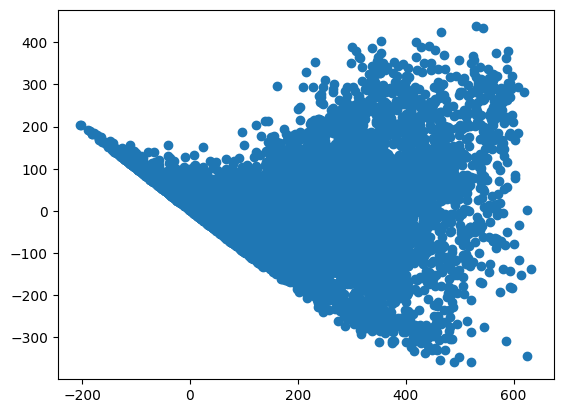

In [52]:
Y_pred=model.predict(x1)
residuals=y-Y_pred

import matplotlib.pyplot as plt
plt.scatter(Y_pred, residuals)
from sklearn.metrics import mean_absolute_error
print(mean_absolute_error(y, Y_pred))

In [53]:
# To improve model
# 1: Add better features , hours may affect demand more
# Check score by adding remove factor likes X = X[["temp", "humidity"]] check how much R^2 comes
# Remove useless factor like workingday
# Handle categorical Values, Regression model treats season[1,2,3,4] or weather like numerical values,
# so when season changes and 1 change in season increase demand by 5, regression will do 1--4 change in season 3*5=15 demand increase which is not true
# Remove outliers
# Test combination effect
# Adjusted R^2
# Look at your Correlation Matrix. If Temp and Humidity are your two strongest predictors, they are the best candidates for an interaction term.

In [54]:
# Lets handle categorical values
# To handle categorical values we actually creates dummy columns
# 1 2 3 4
# 1	0	0	0
# 0	1	0	0
# 0	0	1	0
# 0	0	0	1
# Even if categories were like summer, winter, spring, linear regression can use it [ demand= 5*summer] means nothing
# So you have to assign value and then make dummies for categorical values

# This will find unique values convert it into colums
season_dummies=pd.get_dummies(yulu_data["season"], prefix="season")
month_dummies=pd.get_dummies(yulu_data["M"], prefix="month")
day_dummies=pd.get_dummies(yulu_data["D"], prefix="Day_of_week")
hour_dummies=pd.get_dummies(yulu_data["H"], prefix="Hour")
weather_dummies=pd.get_dummies(yulu_data["weather"],prefix="weather")
temperature_dummies=pd.get_dummies(yulu_data["temp_range"], prefix="temp_range")
humidity_dummies=pd.get_dummies(yulu_data["humidity_range"], prefix="humidity_range")
windspeed_dummies=pd.get_dummies(yulu_data["windspeed_range"], prefix="windspeed_range")
# This is only for regression purpose, so we dont modify the whole table
x2=yulu_data[["Y","M","D","H", "season", "holiday", "workingday", "weather", "temp",
     "humidity", "windspeed"]]
# print(x2["M"].unique())
# print(x2["D"].unique())
# print(x2["H"].unique())
# print(x2["weather"].unique())
#print(x2)
x2=pd.concat([
    x2,
    season_dummies,
    month_dummies,
    day_dummies,
    hour_dummies,
    weather_dummies
], axis=1)
x2=x2.drop(columns=["M", "D", "H", "season", "weather"])
print(x2.head())

      Y  holiday  workingday  temp  humidity  windspeed  season_1  season_2  \
0  2011        0           0  9.84        81        0.0      True     False   
1  2011        0           0  9.02        80        0.0      True     False   
2  2011        0           0  9.02        80        0.0      True     False   
3  2011        0           0  9.84        75        0.0      True     False   
4  2011        0           0  9.84        75        0.0      True     False   

   season_3  season_4  ...  Hour_18  Hour_19  Hour_20  Hour_21  Hour_22  \
0     False     False  ...    False    False    False    False    False   
1     False     False  ...    False    False    False    False    False   
2     False     False  ...    False    False    False    False    False   
3     False     False  ...    False    False    False    False    False   
4     False     False  ...    False    False    False    False    False   

   Hour_23  weather_1  weather_2  weather_3  weather_4  
0    False       

In [55]:
y2=yulu_data["count"]
model1=LinearRegression()
model1.fit(x2, y2)

# for features, coeff_ in zip(x2.columns, model1.coef_):
#   print(features,":", coeff_)

print(model1.score(x2, y2))

0.694454388194623


In [56]:
x3=pd.concat([x2,temperature_dummies, humidity_dummies, windspeed_dummies], axis=1)
#x3=x3.drop(columns=["windspeed"])
#x3=x3.drop(columns=["temp", "humidity", "windspeed"])
print(x3.columns)
print(len(x3.columns))
model2=LinearRegression()
model2.fit(x3, y2)
#print(x3.columns)
# for features, coeff in zip(x3.columns, model3.coef_):
#    print(features,":",coeff)
print(model2.score(x3,y2))

#Dropping temp barely had any effect 0.6983--0.688
#Humidity 0.6983-0.695
#Windspeed 0.698-0.697
#Hour: 0.6983-0.349
#Month:0.698-0.693
#Season:0.698-0.698
#Weather:0.698-0.691
#Day:0.698-0.697
#Holiday:0.698-0.698
#Workingday:0.698-0.698
# H>Y>T>W>M>H>Wind>D

Index(['Y', 'holiday', 'workingday', 'temp', 'humidity', 'windspeed',
       'season_1', 'season_2', 'season_3', 'season_4', 'month_1', 'month_2',
       'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8',
       'month_9', 'month_10', 'month_11', 'month_12', 'Day_of_week_0',
       'Day_of_week_1', 'Day_of_week_2', 'Day_of_week_3', 'Day_of_week_4',
       'Day_of_week_5', 'Day_of_week_6', 'Hour_0', 'Hour_1', 'Hour_2',
       'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8', 'Hour_9',
       'Hour_10', 'Hour_11', 'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15',
       'Hour_16', 'Hour_17', 'Hour_18', 'Hour_19', 'Hour_20', 'Hour_21',
       'Hour_22', 'Hour_23', 'weather_1', 'weather_2', 'weather_3',
       'weather_4', 'temp_range_(0, 10]', 'temp_range_(10, 20]',
       'temp_range_(20, 30]', 'temp_range_(30, 40]', 'temp_range_(40, 50]',
       'humidity_range_(0, 20]', 'humidity_range_(20, 40]',
       'humidity_range_(40, 60]', 'humidity_range_(60, 80]',
       'hu

75

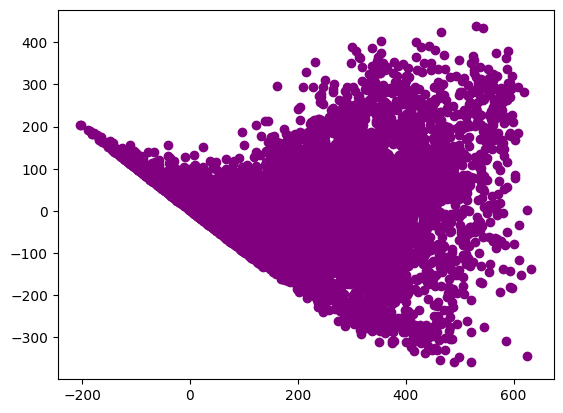

In [57]:
# Residual graph
y_pred3=model2.predict(x3)
residual=y2-y_pred3
plt.scatter(y_pred3, residual, color="purple")
len(x3.columns)

In [58]:
from sklearn.metrics import mean_absolute_error
print(mean_absolute_error(y2, y_pred3))
print(x3.columns)
# MAE = 74
# The model misses the actual demand by about 74 rentals on average.

73.84892594125263
Index(['Y', 'holiday', 'workingday', 'temp', 'humidity', 'windspeed',
       'season_1', 'season_2', 'season_3', 'season_4', 'month_1', 'month_2',
       'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8',
       'month_9', 'month_10', 'month_11', 'month_12', 'Day_of_week_0',
       'Day_of_week_1', 'Day_of_week_2', 'Day_of_week_3', 'Day_of_week_4',
       'Day_of_week_5', 'Day_of_week_6', 'Hour_0', 'Hour_1', 'Hour_2',
       'Hour_3', 'Hour_4', 'Hour_5', 'Hour_6', 'Hour_7', 'Hour_8', 'Hour_9',
       'Hour_10', 'Hour_11', 'Hour_12', 'Hour_13', 'Hour_14', 'Hour_15',
       'Hour_16', 'Hour_17', 'Hour_18', 'Hour_19', 'Hour_20', 'Hour_21',
       'Hour_22', 'Hour_23', 'weather_1', 'weather_2', 'weather_3',
       'weather_4', 'temp_range_(0, 10]', 'temp_range_(10, 20]',
       'temp_range_(20, 30]', 'temp_range_(30, 40]', 'temp_range_(40, 50]',
       'humidity_range_(0, 20]', 'humidity_range_(20, 40]',
       'humidity_range_(40, 60]', 'humidity_range_(60

In [59]:
len(x3.columns)
coefficient=pd.DataFrame({"features":x3.columns, "cof":model2.coef_})
coefficient["abs_cof"]=coefficient["cof"].abs()
coefficient=coefficient.sort_values("abs_cof", ascending=False)
print(coefficient.head(20))

#The biggest drivers we can see just by values without standarzing
# 1)hour(in evening 5-6pm highest demand) 2)temp 3)humidity 4)Windspeed

                    features         cof     abs_cof
46                   Hour_17  260.155617  260.155617
47                   Hour_18  226.655017  226.655017
37                    Hour_8  185.932008  185.932008
33                    Hour_4 -166.707197  166.707197
32                    Hour_3 -165.819942  165.819942
31                    Hour_2 -153.869276  153.869276
34                    Hour_5 -150.491032  150.491032
61       temp_range_(40, 50] -149.066134  149.066134
30                    Hour_1 -142.897735  142.897735
29                    Hour_0 -125.973994  125.973994
48                   Hour_19  115.306588  115.306588
56                 weather_4 -113.844446  113.844446
45                   Hour_16  102.762355  102.762355
52                   Hour_23  -92.510905   92.510905
35                    Hour_6  -91.377907   91.377907
0                          Y   88.875035   88.875035
65   humidity_range_(60, 80]   84.277790   84.277790
64   humidity_range_(40, 60]   81.334460   81.

In [60]:
#Dropping temp barely had any effect 0.6983--0.688
#Humidity 0.6983-0.695
#Windspeed 0.698-0.697
#Hour: 0.6983-0.349
#Month:0.698-0.693
#Season:0.698-0.698
#Weather:0.698-0.691
#Day:0.698-0.697
#Holiday:0.698-0.698
#Workingday:0.698-0.698
# H>Y>T>Weather>M>H>Wind>D

# Hey the main driver look like hour only
#Rank is Hour>>>>>>temp>Weather>Month>Humidity>Wind>Day

In [61]:
from sklearn.model_selection import train_test_split
len(x3.columns)
x4=x3.copy()
len(x4.columns)
x4["temperature_humidity"]=x4["temp"]*x4["humidity"]
x4["humidity_wind"]=x3["windspeed"]*x4["humidity"]
x4["hour_workingday"] = (
    yulu_data["H"] * yulu_data["workingday"]
)

model4=LinearRegression()
x_train , x_test , y_train , y_test=train_test_split(
    x4,y2,
    test_size=0.2,
    random_state=42
)
model4.fit(x_train, y_train)
print(model4.score(x_train,y_train))
print(model4.score(x_test,y_test))

# If you had:
# Train R² = 0.90
# Test R²  = 0.55
# then:
# Model memorized training data.
# Train R² = 0.698
# Test R²  = 0.698
# means:
# The patterns learned from training data
# also exist in unseen data.

0.7042259991240365
0.7053475871235566


In [62]:
m5=LinearRegression()
x5=x4.copy()
x5["temp_square"]=x5["temp"]**2
y5=yulu_data["count"]
x_train5, x_test5, y_train5,y_test5=train_test_split(
    x5, y5,
    test_size=0.2,
    random_state=42
)
m5.fit(x_train5, y_train5)
print(m5.score(x_train5, y_train5))
print(m5.score(x_test5, y_test5))


0.7043726477090757
0.7056252649226906


In [63]:
# Top demand driver:

# Hour of day

# Other important drivers:

# Temperature
# Weather
# Month
# Humidity

# Minimal contribution:

# Holiday
# Workingday
# Season

In [64]:
# Tring Ridge
from sklearn.linear_model import Ridge, Lasso
ridge=Ridge(alpha=1.0)
ridge.fit(x_train5, y_train5)
print(ridge.score(x_train5, y_train5))
print(ridge.score(x_test5, y_test5))

lasso=Lasso(alpha=0.1)
lasso.fit(x_train5, y_train5)
print(lasso.score(x_train5, y_train5))
print(lasso.score(x_test5, y_test5))

#check what lasso removed
# for features, coef in zip(x5.columns, lasso.coef_):
#   print(features,":", coef)

lass_coeff_zero=pd.DataFrame({
    "feature":x5.columns,
    "coef":lasso.coef_
})
print(lass_coeff_zero[lass_coeff_zero["coef"]==0])

0.7042906790957113
0.7056271776999047
0.7032162076645116
0.705222132533277
                             feature  coef
7                           season_2   0.0
11                           month_2  -0.0
17                           month_8  -0.0
24                     Day_of_week_2  -0.0
28                     Day_of_week_6  -0.0
54                         weather_2   0.0
56                         weather_4  -0.0
59               temp_range_(20, 30]   0.0
60               temp_range_(30, 40]  -0.0
61               temp_range_(40, 50]  -0.0
62            humidity_range_(0, 20]  -0.0
63           humidity_range_(20, 40]   0.0
67   windspeed_range_(-0.057, 7.125]  -0.0
70  windspeed_range_(21.374, 28.498]  -0.0
74  windspeed_range_(49.872, 56.997]  -0.0


In [65]:
# Creating degree 2 polynomial and there interaction terms
from sklearn.preprocessing import PolynomialFeatures
poly=PolynomialFeatures(
    degree=2,
    include_bias=False
)
x6=poly.fit_transform(x3)

y6=yulu_data["count"]

x_train6, x_test6, y_train6, y_test6=train_test_split(
    x6, y6,
    test_size=0.2,
    random_state=42
)
m6=LinearRegression()
m6.fit(x_train6, y_train6)
print(m6.score(x_train6, y_train6))
print(m6.score(x_test6,y_test6))

#This is called catastrophic overfitting,
#Data overfitted so much on training data

0.9482555154471891
-3.517671342640149


In [66]:
# When you do:
# y = yulu_data["count"]
# y is typically a view/reference to that Series, not a guaranteed independent copy.
# So do y=yulu_data["count"].copy()

In [ ]:
x_train7, x_test7, y_train7, y_test7=train_test_split(
    x6, y6,
    test_size=0.2,
    random_state=42
)
m7=Lasso(alpha=0.1, max_iter=10000)
m7.fit(x_train7, y_train7)
print(m7.score(x_train7, y_train7))
print(m7.score(x_test7, y_test7))

In [ ]:
import numpy as np
np.sum(m7.coef_!=0)

In [ ]:
features_names=poly.get_feature_names_out(x3.columns)
coeff_array=pd.DataFrame({
    "features":features_names,
    "coef":m7.coef_
})
coeff_array["abs_coef"]=coeff_array["coef"].abs()
feature_lasso_array=coeff_array.sort_values("abs_coef", ascending=False)
feature_lasso_array[["features", "abs_coef"]].head(150)

In [ ]:
y_predict7=m7.predict(x_test7)
print(y_predict7.shape)
print(y6.shape)
mae=mean_absolute_error(y_test7,y_predict7)
print(mae)
residual_1=y_test7-y_predict7
plt.scatter(y_predict7, residual_1, color="green")

In [ ]:
from sklearn.metrics import root_mean_squared_error
rmse=root_mean_squared_error(y_test7, y_predict7)
print(rmse)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error
import numpy as np

# Split data
x_train, x_test, y_train, y_test = train_test_split(
    x6,
    y6,
    test_size=0.2,
    random_state=42
)

# Scale only X
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Try different alpha values
for a in [0.1, 0.3, 0.5, 1, 2]:

    model = Lasso(
        alpha=a,
        max_iter=10000
    )

    # Train
    model.fit(x_train_scaled, y_train)

    # Predict on TEST set
    y_pred = model.predict(x_test_scaled)

    # Metrics
    r2 = model.score(x_test_scaled, y_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)

    # Number of features kept
    active_features = np.sum(model.coef_ != 0)

    print(
        f"alpha={a}",
        f"R²={r2:.3f}",
        f"MAE={mae:.2f}",
        f"RMSE={rmse:.2f}",
        f"active_features={active_features}"
    )

In [ ]:
# Polynomial Features (degree=2)
# +
# Lasso Regression (alpha=0.5)

# Test R² = 0.888
# MAE = 44.7
# Active Features = 711

In [ ]:
# Lets try other models
# Elastic Net
from sklearn.model_selection import train_test_split
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler

poly=PolynomialFeatures(
    degree=2,
    include_bias=False
)
x8=poly.fit_transform(x3)
y8=yulu_data["count"].copy()
print(x8.shape)
print(y8.shape)

m8=ElasticNet(
    alpha=0.5,
    l1_ratio=0.5,
    max_iter=10000
)
x_train8, x_test8, y_train8, y_test8=train_test_split(
    x8, y8,
    test_size=0.2,
    random_state=42
)
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train8)
x_test_scaled=scaler.transform(x_test8)
m8.fit(x_train_scaled, y_train8)
print(m8.score(x_train_scaled, y_train8))
print(m8.score(x_test_scaled, y_test8))

In [ ]:
# Linear Regression        -> scaling optional
# Ridge                    -> scaling important
# Lasso                    -> scaling important
# ElasticNet               -> scaling very important
# No scaling   -> R² ≈ 0.766
# Scaling      -> R² ≈ 0.881
import numpy as np
np.sum(m8.coef_!=0)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

x9=x3.copy()
x9=x9.drop(columns=["temp", "humidity", "windspeed"])
#print(x9.columns)
x_train, x_test, y_train, y_test = train_test_split(
    x9,
    yulu_data["count"],
    test_size=0.2,
    random_state=42
)

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(x_train, y_train)

y_pred = rf.predict(x_test)

print("Train R²:", rf.score(x_train, y_train))
print("Test R²:", rf.score(x_test, y_test))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", root_mean_squared_error(y_test, y_pred))

from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    random_state=42
)

gbr.fit(x_train, y_train)

print("Train R²:", gbr.score(x_train, y_train))
print("Test R²:", gbr.score(x_test, y_test))

# from sklearn.ensemble import ExtraTreesRegressor

# et = ExtraTreesRegressor(
#     n_estimators=300,
#     random_state=42,
#     n_jobs=-1
# )

# et.fit(x_train, y_train)

# print("Train R²:", et.score(x_train, y_train))
# print("Test R²:", et.score(x_test, y_test))

# from lightgbm import LGBMRegressor

# lgbm = LGBMRegressor(
#     n_estimators=500,
#     learning_rate=0.05,
#     random_state=42
# )

# lgbm.fit(x_train, y_train)

# print("Train R²:", lgbm.score(x_train, y_train))
# print("Test R²:", lgbm.score(x_test, y_test))

In [ ]:
feature_importance=pd.DataFrame({
    "feature":x9.columns,
    "importance":rf.feature_importances_
})
feature_importance.sort_values("importance", ascending=False).head(50)


In [ ]:
import joblib
joblib.dump(rf, "yulu_model.pkl")

In [ ]:
print(x9.columns)
print(x9.shape)

In [ ]:
import joblib

joblib.dump(rf, "yulu_model.pkl")
joblib.dump(x9.columns.tolist(), "feature_names.pkl")